<a href="https://colab.research.google.com/github/Harsha1935/MS-Project/blob/main/Stage1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, math, random, warnings, zipfile, shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score
from tqdm import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)


Device: cuda
NumPy: 2.0.2
pandas: 2.2.2
OpenCV: 4.12.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
DATA_ROOT_OR_ZIP = "/content/drive/MyDrive/Dataset.zip"   # e.g., "/content/dr_extracted" or "/content/Dataset.zip"

def ensure_directory_path(p):
    p = Path(p)
    if p.is_dir():
        return str(p)
    if p.is_file() and p.suffix.lower() == ".zip":
        extract_dir = p.with_suffix("")
        if extract_dir.exists():
            shutil.rmtree(extract_dir)
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(p, "r") as z:
            z.extractall(extract_dir)
        print(f" Extracted zip to: {extract_dir}")
        return str(extract_dir)
    raise AssertionError(f"Path is neither a directory nor a .zip: {p}")

DATA_ROOT = ensure_directory_path(DATA_ROOT_OR_ZIP)
print("Using DATA_ROOT:", DATA_ROOT)
print("Top-level entries:", os.listdir(DATA_ROOT)[:12])


 Extracted zip to: /content/drive/MyDrive/Dataset
Using DATA_ROOT: /content/drive/MyDrive/Dataset
Top-level entries: ['colored_images', 'trainLabels.csv']


In [4]:
def detect_layout(root):
    root = Path(root)
    # A) folders per class (0..4)
    for base in ["", "train", "Train", "Training"]:
        d = root / base
        if d.exists():
            sub = [p for p in d.iterdir() if p.is_dir() and p.name.isdigit()]
            if len(sub) >= 2:
                return {"type":"folders", "root":str(d)}
    # B) CSV anywhere
    for r, _, files in os.walk(root):
        if "trainLabels.csv" in files:
            return {"type":"csv", "csv":str(Path(r)/"trainLabels.csv"), "img_root":str(Path(r))}
    return {"type":"unknown"}

layout = detect_layout(DATA_ROOT)
print("Detected layout:", layout)
assert layout["type"] in {"folders","csv"}, "Dataset must be in 0–4 folders or include trainLabels.csv."


Detected layout: {'type': 'csv', 'csv': '/content/drive/MyDrive/Dataset/trainLabels.csv', 'img_root': '/content/drive/MyDrive/Dataset'}


In [5]:
def gather_items_from_folders(root):
    root = Path(root)
    subdirs = [d for d in root.iterdir() if d.is_dir() and d.name.isdigit()]
    assert subdirs, f"No numeric subfolders (0..4) under: {root}"
    items = []
    for d in sorted(subdirs, key=lambda x:int(x.name)):
        for ext in ("*.png","*.jpg","*.jpeg","*.bmp","*.tif","*.tiff"):
            for p in d.glob(ext):
                items.append((str(p), int(d.name)))
    return items

def index_all_images(base):
    base = Path(base)
    idx = {}
    total = 0
    for ext in ("*.png","*.jpg","*.jpeg","*.bmp","*.tif","*.tiff"):
        for p in base.rglob(ext):
            total += 1
            stem = p.stem
            if stem not in idx:
                idx[stem] = str(p)
    print(f"Scanned {total} files; indexed {len(idx)} unique image stems.")
    return idx

def gather_items_from_csv(base):
    base = Path(base)
    csv_path = None
    for r, _, files in os.walk(base):
        if "trainLabels.csv" in files:
            csv_path = Path(r)/"trainLabels.csv"; break
    assert csv_path is not None, "trainLabels.csv not found."

    df = pd.read_csv(csv_path)
    name_col = next((c for c in ["image","img","image_name","id","filename"] if c in df.columns), None)
    label_col = next((c for c in ["level","label","class"] if c in df.columns), None)
    assert name_col and label_col, f"CSV must have image + label columns; got {df.columns.tolist()}"

    stem_to_path = index_all_images(base)
    items, missing = [], []
    for _, r in df.iterrows():
        stem = str(r[name_col]).split('.')[0]
        lab  = int(r[label_col])
        p = stem_to_path.get(stem)
        if p: items.append((p, lab))
        else: missing.append(stem)

    if missing:
        print(f" Missing matches for {len(missing)} rows (first 8): {missing[:8]}")
    return items

if layout["type"] == "folders":
    items = gather_items_from_folders(layout["root"])
else:
    items = gather_items_from_csv(DATA_ROOT)

assert len(items) > 0, "No images found after item building."
print("Sample items:", items[:3])


Scanned 35126 files; indexed 35126 unique image stems.
Sample items: [('/content/drive/MyDrive/Dataset/colored_images/colored_images/No_DR/10_left.png', 0), ('/content/drive/MyDrive/Dataset/colored_images/colored_images/No_DR/10_right.png', 0), ('/content/drive/MyDrive/Dataset/colored_images/colored_images/No_DR/13_left.png', 0)]


In [6]:
# DR label → human name (5 severity levels of ONE disease)
DISEASE_MAP = {
    0: "No Diabetic Retinopathy",
    1: "Mild Diabetic Retinopathy",
    2: "Moderate Diabetic Retinopathy",
    3: "Severe Diabetic Retinopathy",
    4: "Proliferative Diabetic Retinopathy"
}

labels_all = np.array([y for _, y in items])
classes_present = sorted(np.unique(labels_all))

print(f"\nTOTAL images: {len(items)}")
print(f"Classes present ({len(classes_present)}): {classes_present}")
print("Names:")
for c in classes_present:
    print(f"  {c}: {DISEASE_MAP.get(c,'Unknown')}")

overall_counts = pd.Series(labels_all).value_counts().sort_index()
print("\nOverall class distribution:")
for c in classes_present:
    print(f"  {c} ({DISEASE_MAP.get(c)}): {int(overall_counts.get(c,0))}")



TOTAL images: 35126
Classes present (5): [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Names:
  0: No Diabetic Retinopathy
  1: Mild Diabetic Retinopathy
  2: Moderate Diabetic Retinopathy
  3: Severe Diabetic Retinopathy
  4: Proliferative Diabetic Retinopathy

Overall class distribution:
  0 (No Diabetic Retinopathy): 25810
  1 (Mild Diabetic Retinopathy): 2443
  2 (Moderate Diabetic Retinopathy): 5292
  3 (Severe Diabetic Retinopathy): 873
  4 (Proliferative Diabetic Retinopathy): 708


In [7]:
idx_all = np.arange(len(items))
train_idx, tmp_idx = train_test_split(idx_all, test_size=0.30, random_state=SEED, stratify=labels_all)
val_idx, test_idx  = train_test_split(tmp_idx, test_size=0.50, random_state=SEED, stratify=labels_all[tmp_idx])

def print_split(title, idx):
    labs = np.array([items[i][1] for i in idx])
    vc = pd.Series(labs).value_counts().sort_index()
    print(f"\n{title}: {len(idx)} images")
    for c in classes_present:
        print(f"  {c} ({DISEASE_MAP.get(c)}): {int(vc.get(c,0))}")

print_split("Training set",   train_idx)
print_split("Validation set", val_idx)
print_split("Testing set",    test_idx)

print("\n=== SUMMARY ===")
print(f"Train / Val / Test = {len(train_idx)} / {len(val_idx)} / {len(test_idx)}")



Training set: 24588 images
  0 (No Diabetic Retinopathy): 18067
  1 (Mild Diabetic Retinopathy): 1710
  2 (Moderate Diabetic Retinopathy): 3704
  3 (Severe Diabetic Retinopathy): 611
  4 (Proliferative Diabetic Retinopathy): 496

Validation set: 5269 images
  0 (No Diabetic Retinopathy): 3871
  1 (Mild Diabetic Retinopathy): 367
  2 (Moderate Diabetic Retinopathy): 794
  3 (Severe Diabetic Retinopathy): 131
  4 (Proliferative Diabetic Retinopathy): 106

Testing set: 5269 images
  0 (No Diabetic Retinopathy): 3872
  1 (Mild Diabetic Retinopathy): 366
  2 (Moderate Diabetic Retinopathy): 794
  3 (Severe Diabetic Retinopathy): 131
  4 (Proliferative Diabetic Retinopathy): 106

=== SUMMARY ===
Train / Val / Test = 24588 / 5269 / 5269


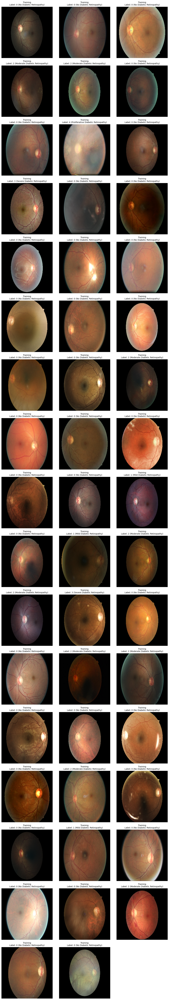

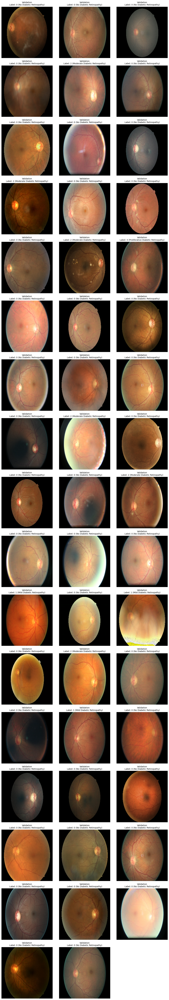

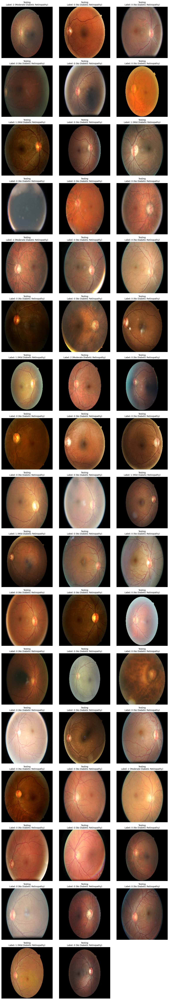

In [8]:
# --- visualize random samples from train, val, and test sets ---
import random
from PIL import Image
import matplotlib.pyplot as plt

# How many images to show from each split
N = 50    # you can change to any number (e.g., 9, 12, 15)

# helper to plot a grid of sample images
def show_samples(split_name, indices, items, n=N):
    sample_idx = random.sample(indices.tolist() if hasattr(indices, "tolist") else list(indices),
                               min(n, len(indices)))
    cols = 3
    rows = math.ceil(len(sample_idx)/cols)
    plt.figure(figsize=(4*cols, 4*rows))
    for i, idx in enumerate(sample_idx, 1):
        img_path, label = items[idx]
        img = Image.open(img_path).convert("RGB")
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{split_name}\nLabel: {label} ({DISEASE_MAP.get(label)})", fontsize=10)
    plt.tight_layout()
    plt.show()

# display samples for each split
show_samples("Training",   train_idx, items)
show_samples("Validation", val_idx,   items)
show_samples("Testing",    test_idx,  items)


In [9]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class DRDataset(Dataset):
    def __init__(self, items, transform=None):
        self.items = items
        self.transform = transform
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        p, y = self.items[idx]
        img = Image.open(p).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, int(y), os.path.basename(p)

IMG_SIZE = 384
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.ColorJitter(0.08,0.08,0.08,0.03),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

train_ds = DRDataset([items[i] for i in train_idx], transform=train_tfms)
val_ds   = DRDataset([items[i] for i in val_idx],   transform=eval_tfms)
test_ds  = DRDataset([items[i] for i in test_idx],  transform=eval_tfms)

# Imbalance-aware sampler
y_train = np.array([items[i][1] for i in train_idx])
class_counts = np.bincount(y_train, minlength=max(classes_present)+1)
class_weights = 1.0 / np.clip(class_counts, 1, None)
sample_weights = class_weights[y_train]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

BATCH = 16
train_loader = DataLoader(train_ds, batch_size=BATCH, sampler=sampler, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)


In [10]:
NUM_CLASSES = len(classes_present)  # should be 5
model = timm.create_model("tf_efficientnet_b0_ns", pretrained=True, num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

In [11]:
# Safe GradScaler for CPU/GPU
from torch.cuda.amp import GradScaler, autocast
scaler = GradScaler(enabled=torch.cuda.is_available())

def epoch_run(loader, train=True):
    model.train(train)
    total, n = 0.0, 0
    y_true, y_prob = [], []
    for x, y, _ in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(train):
            with autocast(enabled=torch.cuda.is_available()):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total += loss.item() * x.size(0)
        n += x.size(0)
        y_true.append(y.detach().cpu().numpy())
        y_prob.append(torch.softmax(logits.detach(), 1).cpu().numpy())

    y_true = np.concatenate(y_true)
    y_prob = np.concatenate(y_prob)
    y_pred = y_prob.argmax(1)
    acc = (y_pred == y_true).mean()
    f1 = f1_score(y_true, y_pred, average="macro")
    return total / max(n, 1), float(acc), float(f1), y_true, y_prob

# --- history containers for plotting ---
history = {
    "epoch": [],
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_f1":   [], "val_f1":   []
}

# keep best epoch's validation predictions for CM/ROC
best_y_true, best_y_prob = None, None

best_f1, wait, patience = -1.0, 0, 5
num_epochs = 50

for ep in range(num_epochs):
    tr_loss, tr_acc, tr_f1, _, _ = epoch_run(train_loader, train=True)
    va_loss, va_acc, va_f1, yv, pv = epoch_run(val_loader,   train=False)

    # log metrics
    history["epoch"].append(ep + 1)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    history["train_f1"].append(tr_f1)
    history["val_f1"].append(va_f1)

    # scheduler (if using ReduceLROnPlateau on val F1)
    try:
        scheduler.step(va_f1)
    except NameError:
        pass  # no scheduler defined

    print(f"Epoch {ep+1:02d} | "
          f"Train {tr_loss:.4f}/{tr_acc:.3f}/{tr_f1:.3f}  ||  "
          f"Val {va_loss:.4f}/{va_acc:.3f}/{va_f1:.3f}")

    # save best
    if va_f1 > best_f1:
        best_f1, wait = va_f1, 0
        best_y_true, best_y_prob = yv.copy(), pv.copy()
        torch.save(model.state_dict(), "best_dr_b0.pth")
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping.")
            break

# load best checkpoint
model.load_state_dict(torch.load("best_dr_b0.pth", map_location=device))
model.eval()
print("Loaded best checkpoint.")


Epoch 01 | Train 1.0552/0.557/0.557  ||  Val 0.8507/0.674/0.433


Epoch 02 | Train 0.7001/0.704/0.700  ||  Val 0.9685/0.593/0.415


Epoch 03 | Train 0.5656/0.761/0.758  ||  Val 1.1371/0.515/0.423


Epoch 04 | Train 0.4719/0.807/0.806  ||  Val 0.8579/0.708/0.468


Epoch 05 | Train 0.4043/0.837/0.837  ||  Val 1.0898/0.617/0.431


Epoch 06 | Train 0.3457/0.861/0.860  ||  Val 0.9832/0.660/0.467


... (11 outputs left out)

Epoch 18 | Train 0.0458/0.983/0.983  ||  Val 1.3387/0.785/0.493


Epoch 19 | Train 0.0454/0.984/0.984  ||  Val 1.2278/0.755/0.494


Epoch 20 | Train 0.0350/0.988/0.988  ||  Val 1.2994/0.780/0.495


Epoch 21 | Train 0.0279/0.990/0.990  ||  Val 1.3524/0.782/0.501
Early stopping.
Loaded best checkpoint.



Classification Report (Test):
                                    precision    recall  f1-score   support

           No Diabetic Retinopathy     0.8328    0.9171    0.8729      3872
         Mild Diabetic Retinopathy     0.1167    0.0765    0.0924       366
     Moderate Diabetic Retinopathy     0.5722    0.4093    0.4772       794
       Severe Diabetic Retinopathy     0.4519    0.3588    0.4000       131
Proliferative Diabetic Retinopathy     0.6344    0.5566    0.5930       106

                          accuracy                         0.7611      5269
                         macro avg     0.5216    0.4637    0.4871      5269
                      weighted avg     0.7303    0.7611    0.7417      5269



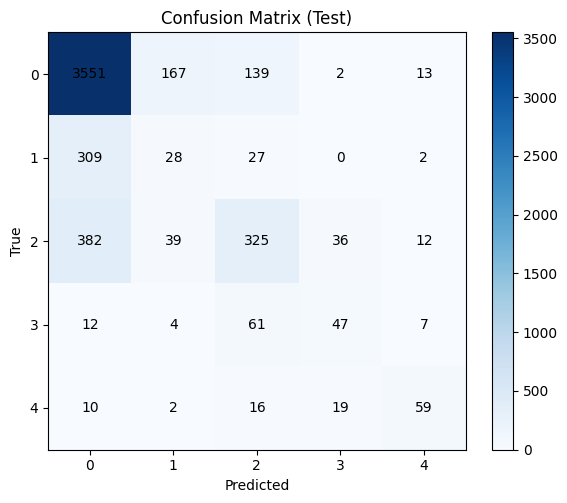

Macro AUROC (OvR): 0.8242


In [12]:
y_true, y_prob, names = [], [], []
with torch.no_grad():
    for x, y, nm in tqdm(test_loader, leave=False):
        logits = model(x.to(device))
        y_prob.append(logits.softmax(1).cpu().numpy())
        y_true.append(y.numpy()); names += list(nm)

y_true = np.concatenate(y_true); y_prob = np.concatenate(y_prob)
y_pred = y_prob.argmax(1)

print("\nClassification Report (Test):")
print(classification_report(y_true, y_pred,
      target_names=[DISEASE_MAP[c] for c in classes_present], digits=4))

cm = confusion_matrix(y_true, y_pred, labels=classes_present)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix (Test)"); plt.colorbar()
plt.xlabel("Predicted"); plt.ylabel("True")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center', color='black')
plt.tight_layout(); plt.show()

# Macro AUROC (OvR)
try:
    y_true_ovr = np.eye(NUM_CLASSES)[y_true]
    auc = roc_auc_score(y_true_ovr, y_prob, average="macro", multi_class="ovr")
    print("Macro AUROC (OvR):", round(auc, 4))
except Exception as e:
    print("AUROC skipped:", e)


Training/Validation curves

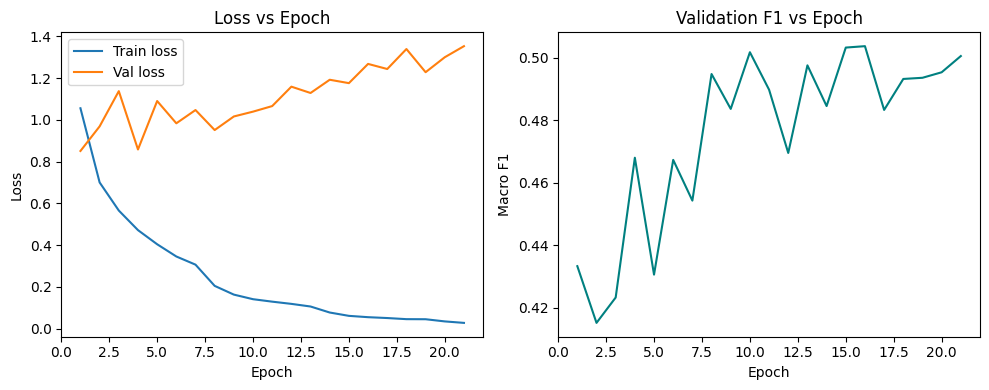

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["epoch"], history["train_loss"], label="Train loss")
plt.plot(history["epoch"], history["val_loss"],   label="Val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss vs Epoch"); plt.legend()

plt.subplot(1,2,2)
plt.plot(history["epoch"], history["val_f1"], color="teal")
plt.xlabel("Epoch"); plt.ylabel("Macro F1"); plt.title("Validation F1 vs Epoch")
plt.tight_layout(); plt.show()


ROC curves (one-vs-rest + macro AUC)

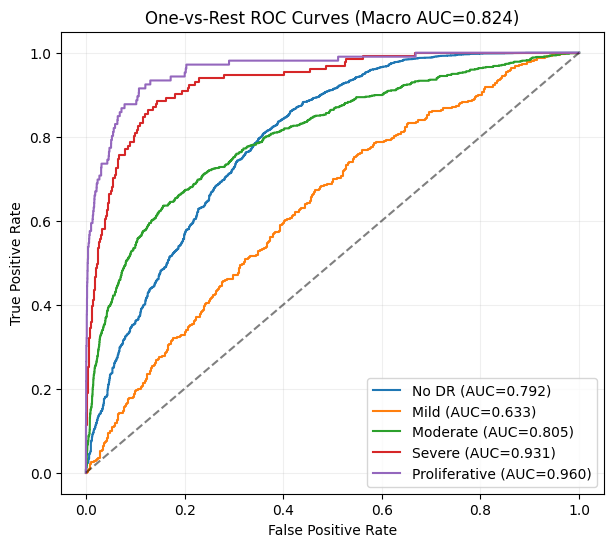

In [14]:
# Define class labels for DR severity levels (0–4)
class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

model.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for x, y, *_ in test_loader:
        x = x.to(device)
        logits = model(x)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)
        all_true.append(y.numpy())

all_probs = np.concatenate(all_probs)
all_true  = np.concatenate(all_true)

plt.figure(figsize=(7,6))
macro_auc = 0
for k, name in enumerate(class_names):
    y_true_k = (all_true == k).astype(int)
    fpr, tpr, _ = roc_curve(y_true_k, all_probs[:,k])
    auc_k = auc(fpr, tpr)
    macro_auc += auc_k
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_k:.3f})")

macro_auc /= len(class_names)
plt.plot([0,1],[0,1],'k--',alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"One-vs-Rest ROC Curves (Macro AUC={macro_auc:.3f})")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()


Reliability diagram + ECE

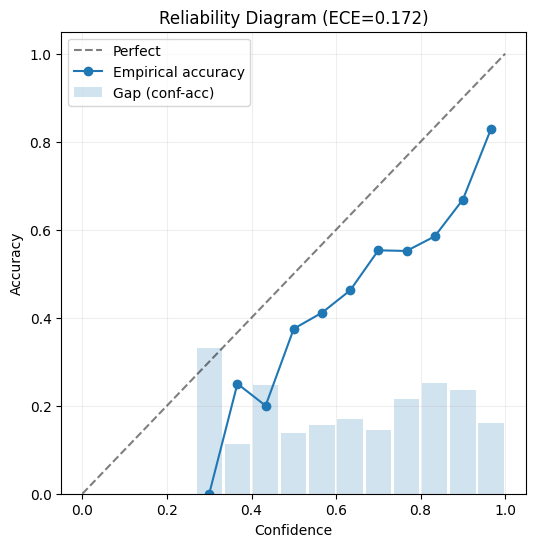

In [15]:
def expected_calibration_error(probs, y_true, n_bins=15):
    confid = probs.max(axis=1)
    preds  = probs.argmax(axis=1)
    accs   = (preds == y_true).astype(float)

    bins = np.linspace(0, 1, n_bins+1)
    ece = 0.0
    bin_centers, bin_acc, bin_conf, bin_count = [], [], [], []

    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        idx = (confid > lo) & (confid <= hi)
        if idx.sum() == 0:
            continue
        bin_conf.append(confid[idx].mean())
        bin_acc.append(accs[idx].mean())
        bin_centers.append((lo+hi)/2)
        bin_count.append(idx.sum())
        ece += np.abs(accs[idx].mean() - confid[idx].mean()) * idx.mean()
    return ece, np.array(bin_centers), np.array(bin_acc), np.array(bin_conf), np.array(bin_count)

ece, centers, acc, conf, cnt = expected_calibration_error(all_probs, all_true, n_bins=15)

plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1],'k--',alpha=0.5,label="Perfect")
plt.plot(centers, acc, marker="o", label="Empirical accuracy")
plt.bar(centers, conf-acc, width=0.06, alpha=0.2, label="Gap (conf-acc)")
plt.xlabel("Confidence"); plt.ylabel("Accuracy")
plt.title(f"Reliability Diagram (ECE={ece:.3f})")
plt.legend(); plt.grid(alpha=0.2); plt.show()


Inference latency distribution

In [16]:
import os, glob, torch, timm

# 1) If you saved to Drive earlier, point here:
SEARCH_ROOTS = [
    ".",  # current folder
    "/content",  # Colab workspace
    "/content/drive/MyDrive",  # Google Drive (adjust if needed)
]

# 2) Look for common names (adjust patterns if you used a different name)
PATTERNS = ["best_dr_b0.pth", "**/best_dr_b0.pth", "*.pth", "**/*.pth"]

def find_checkpoint(roots, patterns):
    for root in roots:
        for pat in patterns:
            hits = glob.glob(os.path.join(root, pat), recursive=True)
            if hits:
                # pick the newest by mtime
                hits.sort(key=lambda p: os.path.getmtime(p), reverse=True)
                return hits[0]
    return None

ckpt = find_checkpoint(SEARCH_ROOTS, PATTERNS)
print("Found checkpoint:", ckpt)

# 3) Recreate the SAME model architecture and load weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = timm.create_model("tf_efficientnet_b0_ns", pretrained=False, num_classes=5).to(device)

if ckpt is None:
    raise FileNotFoundError("No .pth checkpoint found. Make sure you saved it or adjust SEARCH_ROOTS/PATTERNS.")
else:
    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()
    print("Loaded weights from:", ckpt)


Found checkpoint: ./best_dr_b0.pth
Loaded weights from: ./best_dr_b0.pth


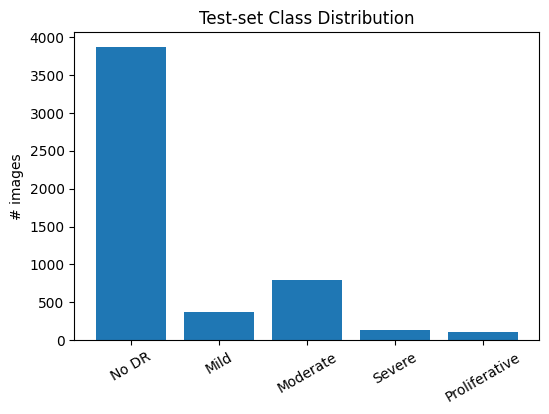

In [17]:
import pandas as pd
counts = pd.Series(all_true).value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar([class_names[i] for i in counts.index], counts.values)
plt.xticks(rotation=30); plt.ylabel("# images")
plt.title("Test-set Class Distribution"); plt.show()


In [18]:
# Add this very early in your app startup, before gradio builds routes
from gradio_client import utils as _gc_utils

_old_get_type = _gc_utils.get_type
def _safe_get_type(schema):
    # Accept boolean schemas (valid in JSON Schema) without blowing up
    if isinstance(schema, bool):
        # Treat as a permissive/forbidden schema; you can return any sentinel
        return "boolean-schema"
    return _old_get_type(schema)

_gc_utils.get_type = _safe_get_type


In [19]:
import fastapi, starlette, pydantic, gradio, gradio_client
print("fastapi", fastapi.__version__)
print("starlette", starlette.__version__)
print("pydantic", pydantic.__version__)
print("gradio", gradio.__version__)
print("gradio_client", gradio_client.__version__)


fastapi 0.121.1
starlette 0.49.3
pydantic 2.11.10
gradio 5.49.1
gradio_client 1.13.3


In [21]:
# 1) Remove libs that force websockets>=13 (not needed for your DR project GUI)
!pip -q uninstall -y google-genai yfinance google-adk dataproc-spark-connect websockets
# 2) Pin a Gradio-compatible websockets
!pip -q install "websockets==12.0"
# 3) Install GUI + XAI without pulling extra deps
!pip -q install --no-deps "gradio==4.44.0" "gradio-client==1.3.0" "torchcam==0.4.0"
# 4) Sanity check
import websockets, gradio, gradio_client
from torchcam.methods import GradCAM
import numpy as np, torch
print("websockets:", websockets.__version__) # -> 12.0
print("gradio:", gradio.__version__) # -> 4.44.0
print("gradio-client:", gradio_client.__version__) # -> 1.3.0
print("torch:", torch.__version__)

websockets: 15.0.1
gradio: 5.49.1
gradio-client: 1.13.3
torch: 2.8.0+cu126


In [22]:
!pip -q install torchcam==0.4.0 gradio==4.44.0


In [23]:
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

# pick the last conv layer automatically (EfficientNet-B0 last conv)
last_conv = None
for m in model.modules():
    if isinstance(m, torch.nn.Conv2d):
        last_conv = m
# fallback: if not found, specify manually one of the final conv layers of your backbone

# preprocessing for a single image
tfm_vis = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

def gradcam_on_pil(pil_img):
    model.zero_grad(set_to_none=True)
    inp = tfm_vis(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(inp)
        probs  = torch.softmax(logits, dim=1)[0].cpu().numpy()
    pred = int(np.argmax(probs))

    # Grad-CAM
    cam_extractor = GradCAM(model, target_layer=last_conv)
    # forward again with grad enabled for cam
    model.zero_grad(set_to_none=True)
    logits = model(inp)
    score  = logits[0, pred]
    score.backward()
    cams = cam_extractor(pred, logits)  # list of cams for target layer(s)
    cam = cams[0].squeeze().detach().cpu()  # HxW

    # normalize and overlay
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    pil_resized = pil_img.resize((cam.shape[1], cam.shape[0])).convert("RGB")
    heatmap = Image.fromarray((plt.cm.jet(cam.numpy())[:,:,:3]*255).astype(np.uint8))
    overlay = Image.blend(pil_resized, heatmap, alpha=0.4)

    return overlay, probs, pred


In [24]:
from __future__ import annotations
import os
from typing import List, Optional

import torch
import torch.nn.functional as F
from torch import nn
from torchvision import models, transforms
from PIL import Image, ImageFont, ImageDraw
import numpy as np
import matplotlib.cm as cm

# --------------------------- Utility: get submodule by dotted name ---------------------------

def get_submodule_by_name(module: nn.Module, name: str) -> nn.Module:
    cur = module
    for part in name.split("."):
        cur = cur[int(part)] if part.isdigit() else getattr(cur, part)
    return cur

# --------------------------- Grad-CAM core ---------------------------

class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.model.eval()
        self.target_layer = target_layer
        self._features: Optional[torch.Tensor] = None
        self._gradients: Optional[torch.Tensor] = None

        def fwd_hook(_, __, out):
            self._features = out.detach()

        def bwd_hook(_, grad_input, grad_output):
            self._gradients = grad_output[0].detach()

        self._fwd_handle = self.target_layer.register_forward_hook(fwd_hook)
        # full_backward_hook is correct for module output grads in PyTorch ≥1.9
        self._bwd_handle = self.target_layer.register_full_backward_hook(bwd_hook)

    def remove_hooks(self):
        self._fwd_handle.remove()
        self._bwd_handle.remove()

    @torch.no_grad()
    def _upsample(self, cam: torch.Tensor, size_hw: tuple[int, int]) -> torch.Tensor:
        cam_up = F.interpolate(cam, size=size_hw, mode="bilinear", align_corners=False)
        cam_up = cam_up.squeeze(0).squeeze(0)  # (H, W)
        cam_up = cam_up.clamp(min=0)
        cam_up -= cam_up.min()
        if cam_up.max() > 0:
            cam_up /= cam_up.max()
        return cam_up

    def __call__(self, logits: torch.Tensor, class_idx: int, input_size_hw: tuple[int, int]) -> np.ndarray:
        if self._features is None:
            raise RuntimeError("Forward hook missed features—did you run a forward pass?")
        self.model.zero_grad(set_to_none=True)
        one_hot = torch.zeros_like(logits)
        one_hot[0, class_idx] = 1.0
        logits.backward(gradient=one_hot, retain_graph=True)
        if self._gradients is None:
            raise RuntimeError("Backward hook missed gradients.")

        grads = self._gradients          # (1, C, Hc, Wc)
        feats = self._features           # (1, C, Hc, Wc)
        weights = grads.mean(dim=(2, 3), keepdim=True)     # (1, C, 1, 1)
        cam = (weights * feats).sum(dim=1, keepdim=True)   # (1, 1, Hc, Wc)
        cam_up = self._upsample(cam, input_size_hw)
        return cam_up.cpu().numpy()

# --------------------------- Visualization helpers ---------------------------

def overlay_heatmap_on_image(img_pil: Image.Image, cam: np.ndarray, alpha: float = 0.45) -> Image.Image:
    img = np.array(img_pil.convert("RGB"))
    h, w = img.shape[:2]
    if cam.shape != (h, w):
        cam = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((w, h), Image.BILINEAR)) / 255.0
    heatmap = (cm.get_cmap("jet")(cam)[..., :3] * 255).astype(np.uint8)
    overlay = (heatmap.astype(np.float32) * alpha + img.astype(np.float32) * (1 - alpha)).astype(np.uint8)
    return Image.fromarray(overlay)

def draw_label_bar(img: Image.Image, top_idxs: List[int], top_probs: List[float], labels: Optional[List[str]] = None) -> Image.Image:
    lines = []
    for i, (idx, p) in enumerate(zip(top_idxs, top_probs), 1):
        name = labels[idx] if labels and 0 <= idx < len(labels) else f"class_{idx}"
        lines.append(f"{i}. {name} — {p*100:.2f}%")

    try:
        font = ImageFont.truetype("DejaVuSans.ttf", 16)
    except Exception:
        font = ImageFont.load_default()

    W, H = img.size
    padding = 8
    temp_draw = ImageDraw.Draw(img)
    line_h = max(font.getbbox("Ag")[3] - font.getbbox("Ag")[1], 16) + 2
    box_h = min(H // 2, padding * 2 + line_h * len(lines))
    box_w = min(W, int(max(temp_draw.textlength(l, font=font) for l in lines) + padding * 2))

    overlay = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    box = Image.new("RGBA", (box_w, box_h), (0, 0, 0, 150))
    overlay.paste(box, (0, H - box_h))
    img_rgba = Image.alpha_composite(img.convert("RGBA"), overlay)

    draw = ImageDraw.Draw(img_rgba)
    y = H - box_h + padding
    for l in lines:
        draw.text((padding, y), l, fill=(255, 255, 255, 255), font=font)
        y += line_h
    return img_rgba.convert("RGB")

# --------------------------- Model loader ---------------------------

def load_model_and_preprocess(model_name: str):
    if hasattr(models, "get_model") and hasattr(models, "get_model_weights"):
        weights_enum = models.get_model_weights(model_name)
        weights = weights_enum.DEFAULT
        model = models.get_model(model_name, weights=weights)
        preprocess = weights.transforms()
        labels = weights.meta.get("categories", None)
        default_target = {
            "resnet": "layer4.2",
            "resnext": "layer4.2",
            "wide_resnet": "layer4.2",
            "densenet": "features.denseblock4",
            "mobilenet_v3": "features.15",
            "efficientnet": "features.7",
            "convnext": "features.7",
            "vit": "encoder.layers.11.ln_1",   # CAM is less meaningful for ViTs
            "swin_v2": "features.6",
        }
        target_guess = "layer4.2"
        for k, v in default_target.items():
            if model_name.startswith(k):
                target_guess = v
                break
        return model, preprocess, labels, target_guess

    # Fallback for very old torchvision
    model = models.resnet50(pretrained=True).eval()
    preprocess = transforms.Compose([
        transforms.Resize(256, interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
    labels = None
    default_target = "layer4.2"
    return model, preprocess, labels, default_target

# --------------------------- Main pipeline ---------------------------

def run_gradcam(
    image_path: str,
    model_name: str = "resnet50",
    target_layer_name: Optional[str] = None,
    topk: int = 5,
    out_path: Optional[str] = "gradcam_overlay.png",
    alpha: float = 0.45,
    show: bool = True,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model, preprocess, labels, default_target = load_model_and_preprocess(model_name)
    model.to(device).eval()

    if target_layer_name is None:
        target_layer_name = default_target
    target_layer = get_submodule_by_name(model, target_layer_name)

    img_pil = Image.open(image_path).convert("RGB")
    W, H = img_pil.size
    x = preprocess(img_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)

    probs = F.softmax(logits, dim=1).squeeze(0)
    k = min(topk, probs.shape[0])
    topk_probs, topk_idxs = torch.topk(probs, k=k)
    topk_probs = topk_probs.tolist()
    topk_idxs = topk_idxs.tolist()

    # Print top-k nicely
    print(f"Top {k} predictions ({model_name}):")
    for i, (idx, p) in enumerate(zip(topk_idxs, topk_probs), 1):
        name = labels[idx] if labels and 0 <= idx < len(labels) else f"class_{idx}"
        print(f"{i:>2}. {name:<30} {p*100:6.2f}%")

    cam_engine = GradCAM(model, target_layer)
    cam = cam_engine(logits, class_idx=topk_idxs[0], input_size_hw=(H, W))
    cam_engine.remove_hooks()

    overlay = overlay_heatmap_on_image(img_pil, cam, alpha=alpha)
    overlay_annot = draw_label_bar(overlay, topk_idxs, topk_probs, labels)

    if out_path:
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
        overlay_annot.save(out_path)
        print(f"\nSaved Grad-CAM overlay to: {out_path}")
    if show:
        display(overlay_annot)

    return {
        "topk_indices": topk_idxs,
        "topk_probs": topk_probs,
        "labels": labels,
        "overlay_image": overlay_annot,
        "cam": cam,  # numpy (H, W) in [0,1]
    }



Discovered classes:
  - Mild (2443 images)
  - Moderate (5292 images)
  - No_DR (25810 images)
  - Proliferate_DR (708 images)
  - Severe (873 images)

Random sample from 'Severe': /content/drive/MyDrive/Dataset/colored_images/colored_images/Severe/36812_right.png
No --ckpt provided. Using ImageNet weights — labels will be unrelated to your DR classes unless you pass --labels-json.
Target layer: layer4

Top-5 predictions:
    1. class_107                   30.09%
    2. class_117                   13.01%
    3. class_111                    1.63%
    4. class_607                    1.57%
    5. class_942                    1.09%

Using top-1 index for CAM: 107


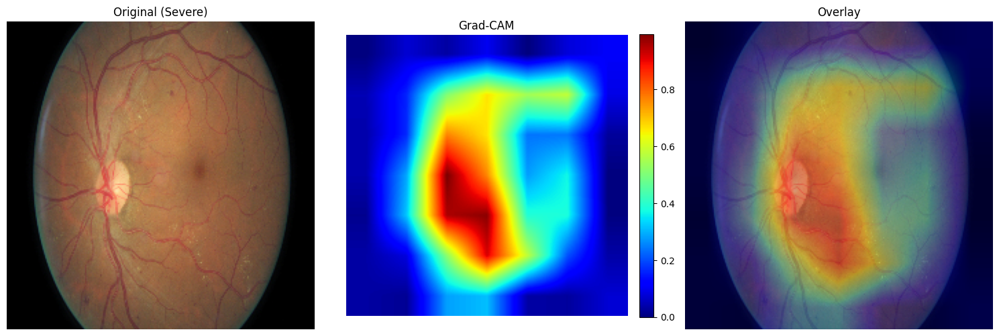

In [47]:
# gradcam_uniform_multiclass_autosample_fixed_seed.py

import os, sys, json, random, argparse
from pathlib import Path
from typing import Optional, Tuple, List, Dict

import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.models as models
import matplotlib.pyplot as plt

# ----------------------------
# Seeding
# ----------------------------
def maybe_seed(seed: int):
    """
    seed >= 0  -> deterministic/reproducible
    seed < 0   -> no seeding (true randomness)
    """
    if seed is None or seed < 0:
        return
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# ----------------------------
# Dataset indexing & sampling
# ----------------------------
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def find_class_dirs(root: Path, max_depth: int = 3) -> List[Path]:
    """
    Find 'class' directories that directly contain images (leaf-ish).
    Handles nested layouts like .../colored_images/colored_images/<Class>/*.png
    """
    root = root.resolve()
    class_dirs = []

    def recurse(cur: Path, depth: int):
        if depth > max_depth:
            return
        subs = [p for p in cur.iterdir() if p.is_dir()]
        files_here = [p for p in cur.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS]
        if files_here:
            class_dirs.append(cur)
            # do NOT recurse further; this is a class folder
            return
        for s in subs:
            recurse(s, depth + 1)

    recurse(root, 0)
    # Deduplicate + ensure each has images under it
    out, seen = [], set()
    for d in class_dirs:
        if str(d) not in seen:
            imgs = [p for p in d.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
            if imgs:
                out.append(d)
                seen.add(str(d))
    return out

def index_dataset(dataset_root: str) -> Dict[str, List[str]]:
    root = Path(dataset_root)
    if not root.exists():
        raise FileNotFoundError(f"Dataset root not found: {dataset_root}")

    class_dirs = find_class_dirs(root, max_depth=3)

    # Fallback: if no class dirs, treat all images under root as one bucket
    if not class_dirs:
        flat_imgs = [str(p) for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
        if not flat_imgs:
            raise FileNotFoundError(f"No images found under: {dataset_root}")
        return {"all": flat_imgs}

    class_to_imgs: Dict[str, List[str]] = {}
    for d in class_dirs:
        cname = d.name
        imgs = [str(p) for p in d.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
        if imgs:
            class_to_imgs[cname] = imgs

    if not class_to_imgs:
        raise FileNotFoundError(f"No class folders with images found under: {dataset_root}")
    return class_to_imgs

def list_classes(class_to_imgs: Dict[str, List[str]]) -> List[str]:
    return sorted(class_to_imgs.keys())

def sample_image(
    class_to_imgs: Dict[str, List[str]],
    class_name: Optional[str] = None,
    pick_mode: str = "uniform",   # 'uniform' (per-class) or 'weighted' (by image count)
) -> Tuple[str, str]:
    if class_name:
        if class_name not in class_to_imgs:
            raise ValueError(f"--class-name '{class_name}' not found. Available: {list_classes(class_to_imgs)}")
        chosen_cls = class_name
        return chosen_cls, random.choice(class_to_imgs[chosen_cls])

    classes = list_classes(class_to_imgs)
    if len(classes) == 1:
        chosen_cls = classes[0]
        return chosen_cls, random.choice(class_to_imgs[chosen_cls])

    if pick_mode == "uniform":
        chosen_cls = random.choice(classes)         # truly uniform over classes
        return chosen_cls, random.choice(class_to_imgs[chosen_cls])
    elif pick_mode == "weighted":
        all_pairs = [(c, p) for c, lst in class_to_imgs.items() for p in lst]
        return random.choice(all_pairs)
    else:
        raise ValueError("--pick-mode must be 'uniform' or 'weighted'")

# ----------------------------
# Grad-CAM (forward hook + autograd.grad)
# ----------------------------
class GradCAM:
    def __init__(self, model: nn.Module, target_module: nn.Module):
        self.model = model
        self.target_module = target_module
        self.hook = None
        self.activations = None

        def fwd_hook(_m, _inp, out):
            if isinstance(out, torch.Tensor):
                out.requires_grad_(True)
            self.activations = out

        self.hook = self.target_module.register_forward_hook(fwd_hook)

    @torch.no_grad()
    def remove(self):
        if self.hook is not None:
            self.hook.remove()
            self.hook = None

    def __call__(self, logits: torch.Tensor, class_idx: int, upsample_hw: Tuple[int, int]) -> np.ndarray:
        if self.activations is None:
            raise RuntimeError("Target activations were not captured. Check --target-layer path and ensure hook before forward().")

        H, W = upsample_hw
        with torch.enable_grad():
            score = logits[:, class_idx].sum()
            grads = torch.autograd.grad(
                outputs=score,
                inputs=self.activations,
                retain_graph=True,
                create_graph=False,
                allow_unused=False
            )[0]  # [B,C,h,w]

        weights = grads.mean(dim=(2, 3), keepdim=True)       # [B,C,1,1]
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam -= cam.amin(dim=(2, 3), keepdim=True)
        cam /= cam.amax(dim=(2, 3), keepdim=True).clamp_min(1e-6)

        cam_up = F.interpolate(cam, size=(H, W), mode="bilinear", align_corners=False)
        return cam_up[0, 0].detach().cpu().numpy()

# ----------------------------
# Model / I/O helpers
# ----------------------------
def get_module_by_name(model: nn.Module, name: str) -> nn.Module:
    cur = model
    for part in name.split("."):
        if not part:
            continue
        if part.isdigit():
            cur = cur[int(part)]
        else:
            cur = getattr(cur, part)
    return cur

def build_model(arch: str, num_classes: int, ckpt: str) -> nn.Module:
    arch = arch.lower()
    if arch == "resnet50":
        try:
            model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        except Exception:
            model = models.resnet50(weights=None)
    elif arch == "resnet18":
        try:
            model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        except Exception:
            model = models.resnet18(weights=None)
    else:
        raise ValueError("Supported --arch: resnet50, resnet18")

    if num_classes != 1000:
        if hasattr(model, "fc") and isinstance(model.fc, nn.Linear):
            in_f = model.fc.in_features
            model.fc = nn.Linear(in_f, num_classes)
        else:
            raise ValueError("This script expects a torchvision ResNet with .fc")

    if ckpt:
        if not os.path.isfile(ckpt):
            raise FileNotFoundError(f"Checkpoint not found: {ckpt}")
        state = torch.load(ckpt, map_location="cpu")
        sd = state.get("state_dict", state)
        sd = {k.replace("module.", ""): v for k, v in sd.items()}
        missing, unexpected = model.load_state_dict(sd, strict=False)
        print(f"Loaded ckpt (missing={len(missing)}, unexpected={len(unexpected)})")

    return model

def load_labels(labels_json: Optional[str], num_classes: int) -> List[str]:
    if labels_json and os.path.isfile(labels_json):
        with open(labels_json, "r") as f:
            data = json.load(f)
        if isinstance(data, dict):
            return [data.get(str(i), f"class_{i}") for i in range(num_classes)]
        if isinstance(data, list):
            lab = [str(x) for x in data]
            if len(lab) < num_classes:
                lab += [f"class_{i}" for i in range(len(lab), num_classes)]
            return lab
    return [f"class_{i}" for i in range(num_classes)]

def load_image(image_path: str, img_size: int) -> Tuple[Image.Image, torch.Tensor]:
    pil = Image.open(image_path).convert("RGB")
    t = T.Compose([
        T.Resize((img_size, img_size), interpolation=T.InterpolationMode.BILINEAR),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])(pil).unsqueeze(0)
    return pil, t

def apply_colormap_on_image(img_pil: Image.Image, cam: np.ndarray, alpha: float = 0.35) -> Image.Image:
    cam_uint8 = np.uint8(np.clip(cam, 0, 1) * 255)
    cmap = plt.get_cmap("jet")(cam_uint8)[..., :3]
    heat = (cmap * 255).astype(np.uint8)
    heat_pil = Image.fromarray(heat).resize(img_pil.size, Image.BILINEAR)

    base = np.array(img_pil).astype(np.float32)
    blend = alpha * np.array(heat_pil, dtype=np.float32) + (1 - alpha) * base
    blend = np.clip(blend, 0, 255).astype(np.uint8)
    return Image.fromarray(blend)

def print_topk(probs: torch.Tensor, idx_to_name: List[str], k: int = 5) -> int:
    topv, topi = probs.topk(k, dim=1)
    topv = topv[0].cpu().numpy()
    topi = topi[0].cpu().numpy()
    print("\nTop-{} predictions:".format(k))
    for r, (v, i) in enumerate(zip(topv, topi), 1):
        name = idx_to_name[int(i)] if int(i) < len(idx_to_name) else f"class_{int(i)}"
        print(f"  {r:>3}. {name:<26s} {100.0*float(v):6.2f}%")
    return int(topi[0])

# ----------------------------
# CLI
# ----------------------------
def parse_args(argv=None):
    p = argparse.ArgumentParser(
        description="Grad-CAM overlay + predicted probabilities (uniform class sampling; nested class dirs supported)"
    )
    p.add_argument("--dataset-root", type=str,
                   default="/content/drive/MyDrive/Dataset/colored_images/colored_images",
                   help="Root that contains class folders (leaf dirs with images).")
    p.add_argument("--class-name", type=str, default="",
                   help="Force sampling from a specific class folder name.")
    p.add_argument("--pick-mode", type=str, default="uniform", choices=["uniform", "weighted"],
                   help="uniform = sample class uniformly; weighted = sample over all images (class-size weighted).")
    p.add_argument("--image", type=str, default="",
                   help="Optional explicit image path; overrides sampling if set.")
    p.add_argument("--arch", type=str, default="resnet50", choices=["resnet50", "resnet18"])
    p.add_argument("--num-classes", type=int, default=1000)
    p.add_argument("--ckpt", type=str, default="")
    p.add_argument("--target-layer", type=str, default="",
                   help="e.g. 'layer4', 'layer4.1', 'layer4.2.conv3'. Default: layer4")
    p.add_argument("--img-size", type=int, default=224)
    p.add_argument("--topk", type=int, default=5)
    p.add_argument("--alpha", type=float, default=0.35)
    p.add_argument("--out", type=str, default="gradcam_overlay.png")
    p.add_argument("--labels-json", type=str, default="")
    p.add_argument("--seed", type=int, default=-1,    # <<<< default: NO seeding (true randomness)
                   help="Set >=0 for reproducible sampling; <0 keeps it random every run.")
    p.add_argument("--list-classes", action="store_true",
                   help="List discovered class folders and exit.")
    return p.parse_args(argv)

# ----------------------------
# Main
# ----------------------------
def main(argv=None):
    # Strip Jupyter's injected -f <kernel.json>
    if argv is None and len(sys.argv) > 1 and sys.argv[1].startswith("-f"):
        argv = []

    args = parse_args(argv)
    maybe_seed(args.seed)

    # 1) Index & (optional) list classes
    class_to_imgs = index_dataset(args.dataset_root)
    classes = list_classes(class_to_imgs)
    print("Discovered classes:")
    for c in classes:
        print(f"  - {c} ({len(class_to_imgs[c])} images)")
    if args.list_classes:
        return

    # 2) Choose image
    if args.image and os.path.isfile(args.image):
        chosen_cls = Path(args.image).parent.name
        img_path = args.image
    else:
        chosen_cls, img_path = sample_image(
            class_to_imgs,
            class_name=(args.class_name if args.class_name else None),
            pick_mode=args.pick_mode,
        )
        print(f"\nRandom sample from '{chosen_cls}': {img_path}")

    # 3) Build model
    if not args.ckpt:
        print("No --ckpt provided. Using ImageNet weights — labels will be unrelated to your DR classes unless you pass --labels-json.")
    model = build_model(args.arch, args.num_classes, args.ckpt)
    model.eval()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # 4) Target layer & hooks BEFORE forward
    target_module = get_module_by_name(model, args.target_layer) if args.target_layer else model.layer4
    print(f"Target layer: {args.target_layer if args.target_layer else 'layer4'}")
    cam_engine = GradCAM(model, target_module)

    # 5) Load image
    img_pil, img_t = load_image(img_path, args.img_size)
    img_t = img_t.to(device)
    H, W = img_pil.size[1], img_pil.size[0]

    # 6) Forward
    logits = model(img_t)                     # [1, C]
    probs = logits.softmax(dim=1).detach()

    # 7) Top-k pretty print
    idx_to_name = load_labels(args.labels_json, logits.shape[1])
    top1_idx = print_topk(probs, idx_to_name, k=args.topk)
    print(f"\nUsing top-1 index for CAM: {top1_idx}")

    # 8) Grad-CAM
    cam = cam_engine(logits, class_idx=int(top1_idx), upsample_hw=(H, W))
    cam_engine.remove()

    # 9) Overlay + save + show
    overlay = apply_colormap_on_image(img_pil, cam, alpha=args.alpha)
    overlay.save(args.out)

    # Show inline (Colab/Jupyter)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_pil); axes[0].set_title(f"Original ({chosen_cls})"); axes[0].axis("off")
    im1 = axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    axes[2].imshow(overlay); axes[2].set_title("Overlay"); axes[2].axis("off")
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    main()



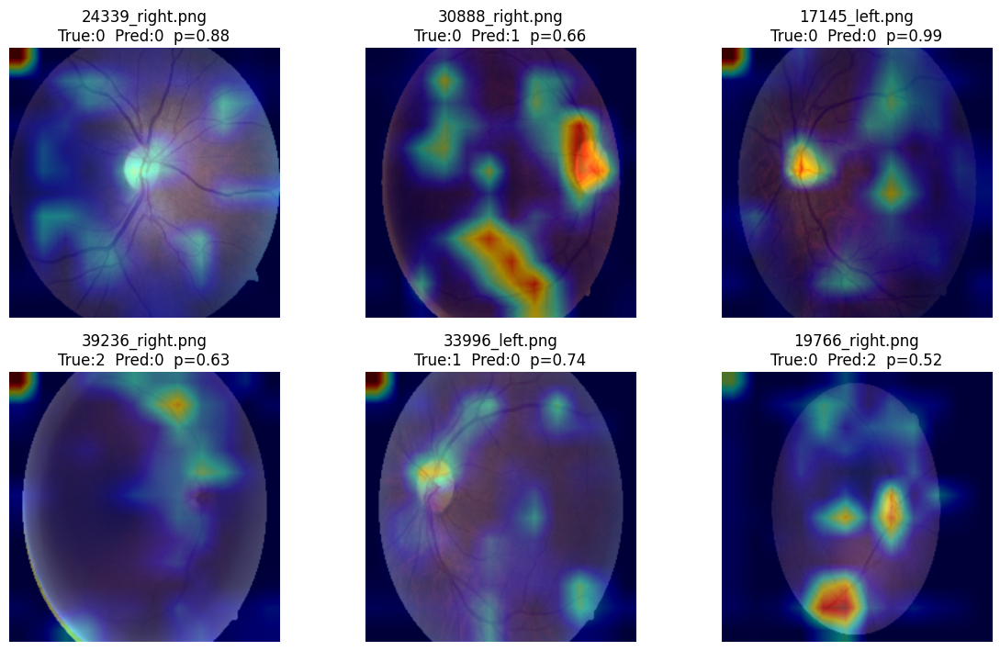

In [48]:
import torch
import torch.nn as nn
import numpy as np
import cv2
import matplotlib.pyplot as plt

# -------- utils: find last Conv2d, de-normalize, overlay ----------
def find_last_conv(module: nn.Module):
    last = None
    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            last = m
    assert last is not None, "No Conv2d found in model"
    return last

def denorm_batch(x):
    """x: (B,3,H,W) normalized with ImageNet stats -> back to [0,1]"""
    mean = torch.tensor([0.485,0.456,0.406], device=x.device).view(1,3,1,1)
    std  = torch.tensor([0.229,0.224,0.225], device=x.device).view(1,3,1,1)
    return (x * std + mean).clamp(0,1)

def heat_to_rgb(heat):
    """heat: (H,W) in [0,1] -> color heatmap (H,W,3) uint8"""
    h255 = (heat*255.0).astype(np.uint8)
    col = cv2.applyColorMap(h255, cv2.COLORMAP_JET)
    col = cv2.cvtColor(col, cv2.COLOR_BGR2RGB)
    return col

def overlay_rgb(rgb01, heat_rgb, alpha=0.45):
    """rgb01: float [0,1], heat_rgb: uint8 [0,255]"""
    base = (rgb01*255.0).astype(np.uint8)
    out = ( (1-alpha)*base + alpha*heat_rgb ).astype(np.uint8)
    return out

# -------- minimal Grad-CAM implementation (predicted class) --------
class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.hook_a = target_layer.register_forward_hook(self._forward_hook)
        self.hook_g = target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inp, out):
        # save activations (B,C,h,w)
        self.activations = out.detach()

    def _backward_hook(self, module, grad_in, grad_out):
        # grad_out is a tuple; take grads wrt activations (B,C,h,w)
        self.gradients = grad_out[0].detach()

    @torch.no_grad()
    def _normalize_cam(self, cam):
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

    def __call__(self, x: torch.Tensor, target_index=None):
        """
        x: (B,3,H,W) normalized
        target_index: int or list per sample; if None -> use argmax
        returns: list of heatmaps (H,W) in [0,1]
        """
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)  # (B,K)
        if target_index is None:
            target_index = logits.argmax(dim=1)

        # build scalar targets for backward (sum over batch)
        selected = logits[torch.arange(x.size(0), device=x.device), target_index]
        selected.sum().backward()

        # activations: (B,C,h,w), gradients: (B,C,h,w)
        acts = self.activations           # (B,C,h,w)
        grads = self.gradients            # (B,C,h,w)

        B, C, h, w = acts.shape
        cams = []
        for b in range(B):
            # weights: channel-wise average of grads over spatial dims
            w_k = grads[b].mean(dim=(1,2))              # (C,)
            cam = (w_k.view(C,1,1) * acts[b]).sum(0)    # (h,w)

            cam = torch.relu(cam)                       # ReLU per Grad-CAM
            cam = cam.cpu().numpy()
            cam = cv2.resize(cam, (x.size(3), x.size(2)))  # to input H,W
            cam = self._normalize_cam(cam)
            cams.append(cam)
        return cams, logits.softmax(1).detach().cpu().numpy()

    def close(self):
        self.hook_a.remove()
        self.hook_g.remove()

# -------- run Grad-CAM on a few test images ----------
model.eval()
target_layer = find_last_conv(model)
gc = GradCAM(model, target_layer)

k = min(6, len(test_ds))  # number of images to visualize
idxs = np.random.choice(len(test_ds), size=k, replace=False)

ncols = 3
nrows = int(np.ceil(k / ncols))
plt.figure(figsize=(4*ncols, 3.6*nrows))
pos = 1

for i in idxs:
    img, true_lab, name = test_ds[i]
    x = img.unsqueeze(0).to(device)  # (1,3,H,W)

    cams, probs = gc(x)
    cam = cams[0]                     # (H,W) in [0,1]
    prob = probs[0]
    pred = int(prob.argmax())

    # de-normalize and overlay
    rgb01 = denorm_batch(x).squeeze(0).permute(1,2,0).cpu().numpy()
    heat_rgb = heat_to_rgb(cam)
    over = overlay_rgb(rgb01, heat_rgb, alpha=0.45)

    plt.subplot(nrows, ncols, pos); pos += 1
    plt.imshow(over); plt.axis('off')
    plt.title(f"{name}\nTrue:{true_lab}  Pred:{pred}  p={prob[pred]:.2f}")

plt.tight_layout(); plt.show()

gc.close()
